In [1]:
import numpy as np
import scipy.io as sio
import scipy.ndimage
from netCDF4 import Dataset
import matplotlib.pyplot as plt
from pyproj import Proj, transform
from scipy.io import loadmat
from netCDF4 import Dataset
import xarray as xr
import os

lidar_chm.shape (1274, 12953)
ground_range_axis (1274, 1)
azimuth_axis (1, 12953)
ground_range_axis.min 606.0
ground_range_axis.max 4425.0
azimuth_axis.min -3400.5
azimuth_axis.max 3075.5


<function matplotlib.pyplot.show(close=None, block=None)>

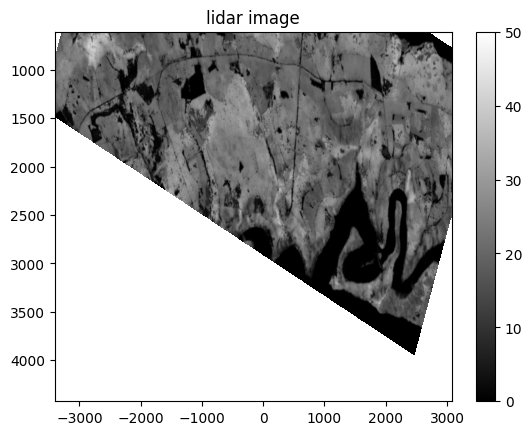

In [2]:
# load lidar chm data
lidar_NW_path = '/home/takataka_ju/data/lidar_chm/CHM_lidar_NW_radar_coord.mat'
lidar_SE_path = '/home/takataka_ju/data/lidar_chm/CHM_lidar_SE_radar_coord.mat'

lidar_radar = loadmat(lidar_NW_path) ## change NW or SE

lidar_chm = lidar_radar['CHM_lidar']
ground_range_axis_lidar = lidar_radar['ground_range_axis']
azimuth_axis_lidar = lidar_radar['azimuth_axis']

print('lidar_chm.shape', lidar_chm.shape)
print('ground_range_axis', ground_range_axis_lidar.shape)
print('azimuth_axis', azimuth_axis_lidar.shape)

print('ground_range_axis.min', ground_range_axis_lidar.min())
print('ground_range_axis.max', ground_range_axis_lidar.max())
print('azimuth_axis.min', azimuth_axis_lidar.min())
print('azimuth_axis.max', azimuth_axis_lidar.max())

# plt.imshow(lidar_chm, cmap="gray", vmin=0, vmax=50, aspect='auto')
plt.imshow(lidar_chm, cmap="gray", vmin=0, vmax=50, aspect='auto', extent=[azimuth_axis_lidar.min(), azimuth_axis_lidar.max(), ground_range_axis_lidar.max(), ground_range_axis_lidar.min()])
plt.colorbar()
plt.title("lidar image")
plt.show

lidar_chm.shape (1274, 12953)
ground_range_axis (1274, 1)
azimuth_axis (1, 12953)
ground_range_axis.min 606.0
ground_range_axis.max 4425.0
azimuth_axis.min -3400.5
azimuth_axis.max 3075.5


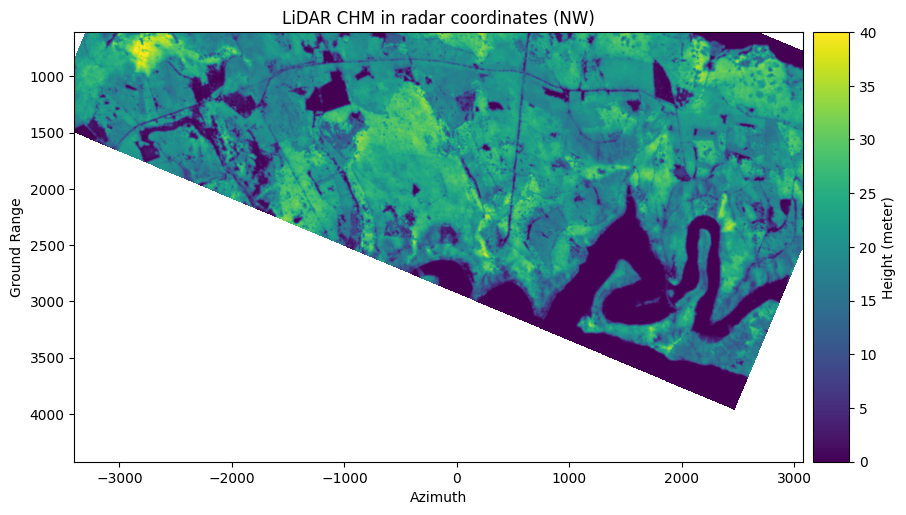

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Load lidar chm data
lidar_NW_path = '/home/takataka_ju/data/lidar_chm/CHM_lidar_NW_radar_coord.mat'
lidar_SE_path = '/home/takataka_ju/data/lidar_chm/CHM_lidar_SE_radar_coord.mat'

lidar_radar = loadmat(lidar_NW_path)  # Change NW or SE as needed

lidar_chm = lidar_radar['CHM_lidar']
ground_range_axis_lidar = lidar_radar['ground_range_axis']
azimuth_axis_lidar = lidar_radar['azimuth_axis']

print('lidar_chm.shape', lidar_chm.shape)
print('ground_range_axis', ground_range_axis_lidar.shape)
print('azimuth_axis', azimuth_axis_lidar.shape)

print('ground_range_axis.min', ground_range_axis_lidar.min())
print('ground_range_axis.max', ground_range_axis_lidar.max())
print('azimuth_axis.min', azimuth_axis_lidar.min())
print('azimuth_axis.max', azimuth_axis_lidar.max())

# Plotting
plt.figure(figsize=(10, 6))
ax = plt.gca()  # Get the current Axes instance

# Plot the lidar CHM data
im = ax.imshow(lidar_chm, cmap="viridis", vmin=0, vmax=40,
               extent=[azimuth_axis_lidar.min(), azimuth_axis_lidar.max(), 
                       ground_range_axis_lidar.max(), ground_range_axis_lidar.min()])

# Create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be 0.1 inch.
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)

# Create color bar in the new axis
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Height (meter)')

ax.set_xlabel('Azimuth')
ax.set_ylabel('Ground Range')
ax.set_title('LiDAR CHM in radar coordinates (NW)')

plt.show()


In [4]:
slc_fullpath_NW = os.path.join('/home/takataka_ju/data/sar-netcdf/P/NW/SLC/PoliMi/SAR_CPLX_20200722071511_435.0M_HH_12_pres_16_fdc_0.sar.refoc.nc')
slc_fullpath_SE = os.path.join('/home/takataka_ju/data/sar-netcdf/P/SE/SLC/PoliMi/SAR_CPLX_20200722072057_435.0M_HH_12_pres_16_fdc_0.sar.refoc.nc')

# slc_fullpath_NW
# Size: CrossRange: 12953, GroundRange: 1274
# Cross Range (azimuth_axis) Min: -3400.5, Max: 3075.5
# Ground Range (ground_range_axis) Min: 606, Max: 4425

# slc_fullpath_SE
# Size: CrossRange: 13530, GroundRange: 1306
# Cross Range (azimuth_axis) Min: -3646, Max: 3118.5
# Ground Range (ground_range_axis) Min: 510, Max: 4425

In [5]:
nc_data = xr.open_dataset(slc_fullpath_NW)

In [6]:
azimuth_axis_slc = nc_data.variables['CrossRange']
ground_range_axis_slc = nc_data.variables['GroundRange']

print('azimuth_axis:', azimuth_axis_slc.shape)
print('azimuth_axis min:', azimuth_axis_slc.min())
print('azimuth_axis max:', azimuth_axis_slc.max())
print('ground_range_axis:', ground_range_axis_slc.shape)
print('ground_range_axis min:', ground_range_axis_slc.min())
print('ground_range_axis max:', ground_range_axis_slc.max())

azimuth_axis: (12953,)
azimuth_axis min: <xarray.Variable ()> Size: 4B
array(-3400.5, dtype=float32)
azimuth_axis max: <xarray.Variable ()> Size: 4B
array(3075.5, dtype=float32)
ground_range_axis: (1274,)
ground_range_axis min: <xarray.Variable ()> Size: 4B
array(606., dtype=float32)
ground_range_axis max: <xarray.Variable ()> Size: 4B
array(4425., dtype=float32)


BC (12953, 1274)


<function matplotlib.pyplot.show(close=None, block=None)>

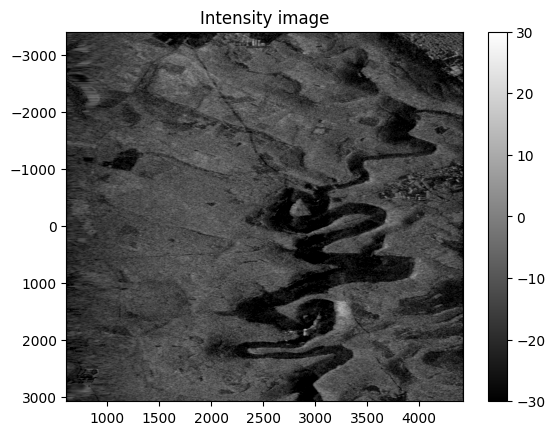

In [7]:
import matplotlib.pyplot as plt
# reads a single netCDF file
RealPart_SAR_CPLX = nc_data.variables['SigmaImageSingleLookRealPart'].to_numpy()
RealPart_SAR_CPLX_2 = RealPart_SAR_CPLX ** 2
ImagPart_SAR_CPLX = nc_data.variables["SigmaImageSingleLookImagPart"].to_numpy()
ImagPart_SAR_CPLX_2 = ImagPart_SAR_CPLX ** 2
DN_2 = RealPart_SAR_CPLX_2 + ImagPart_SAR_CPLX_2
DN = np.sqrt(DN_2)
BC = 10*np.log(DN)
print('BC', BC.shape)
# plt.imshow(BC, cmap="gray", vmin=-30, vmax=30, aspect='auto')
plt.imshow(BC, cmap="gray", vmin=-30, vmax=30, aspect='auto', extent=[ground_range_axis_slc.min(), ground_range_axis_slc.max(), azimuth_axis_slc.max(), azimuth_axis_slc.min()])
plt.colorbar()

plt.title("Intensity image")
plt.show

In [8]:
# lidar_chm = lidar_radar['CHM_lidar']
# ground_range_axis_lidar = lidar_radar['ground_range_axis']
# azimuth_axis_lidar = lidar_radar['azimuth_axis']

# azimuth_axis_slc = nc_data.variables['CrossRange'][:]
# ground_range_axis_slc = nc_data.variables['GroundRange'][:]

azimuth_axis_lidar_matrix, ground_range_axis_lidar_matrix = np.meshgrid(azimuth_axis_lidar, ground_range_axis_lidar)
azimuth_axis_slc_matrix, ground_range_axis_slc_matrix = np.meshgrid(azimuth_axis_slc, ground_range_axis_slc)

In [12]:
print(type(lidar_chm))
lidar_chm.shape

<class 'numpy.ndarray'>


(1274, 12953)

## Crop LiDAR dataset in radar coordinates

### Crop for NW 

lidar_chm.shape (1274, 12953)
ground_range_axis (1274, 1)
azimuth_axis (1, 12953)
ground_range_axis.min 606.0
ground_range_axis.max 4425.0
azimuth_axis.min -3400.5
azimuth_axis.max 3075.5


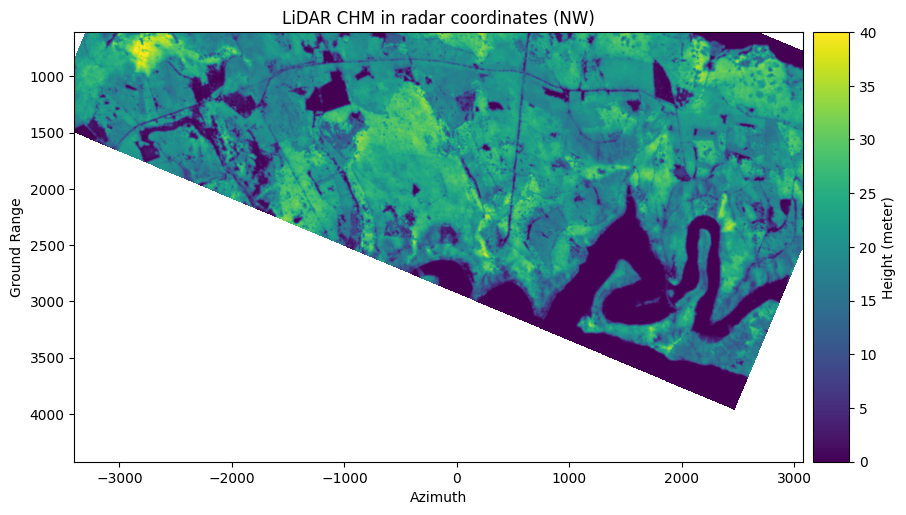

In [16]:
lidar_radar = loadmat(lidar_NW_path)  # Change NW or SE as needed

lidar_chm = lidar_radar['CHM_lidar']
ground_range_axis_lidar = lidar_radar['ground_range_axis']
azimuth_axis_lidar = lidar_radar['azimuth_axis']

print('lidar_chm.shape', lidar_chm.shape)
print('ground_range_axis', ground_range_axis_lidar.shape)
print('azimuth_axis', azimuth_axis_lidar.shape)

print('ground_range_axis.min', ground_range_axis_lidar.min())
print('ground_range_axis.max', ground_range_axis_lidar.max())
print('azimuth_axis.min', azimuth_axis_lidar.min())
print('azimuth_axis.max', azimuth_axis_lidar.max())

# Plotting
plt.figure(figsize=(10, 6))
ax = plt.gca()  # Get the current Axes instance

# Plot the lidar CHM data
im = ax.imshow(lidar_chm, cmap="viridis", vmin=0, vmax=40,
               extent=[azimuth_axis_lidar.min(), azimuth_axis_lidar.max(), 
                       ground_range_axis_lidar.max(), ground_range_axis_lidar.min()])

# Create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be 0.1 inch.
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)

# Create color bar in the new axis
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Height (meter)')

ax.set_xlabel('Azimuth')
ax.set_ylabel('Ground Range')
ax.set_title('LiDAR CHM in radar coordinates (NW)')

plt.show()

In [40]:
from shapely.geometry import Point, Polygon
# Define the coordinates of the polygon (example polygon coordinates)
polygon_coords = [(0, 250), (150, 0), (10800, 0), (12953, 130), (12953, 650), (12000, 1000), (7100, 780), (0, 280)]
polygon = Polygon(polygon_coords)

In [41]:
# Access the correct coordinate variables (assuming they are named 'x' and 'y')
rows, cols = lidar_chm.shape
mask = np.zeros(lidar_chm.shape, dtype=bool)

In [42]:
x_coords, y_coords = np.meshgrid(np.arange(cols), np.arange(rows))

In [43]:
import xarray as xr
from matplotlib.patches import Polygon as MplPolygon

# Check if each point is inside the polygon
for i in range(rows):
    for j in range(cols):
        point = Point(x_coords[i, j], y_coords[i, j])
        if polygon.contains(point):
            mask[i, j] = True

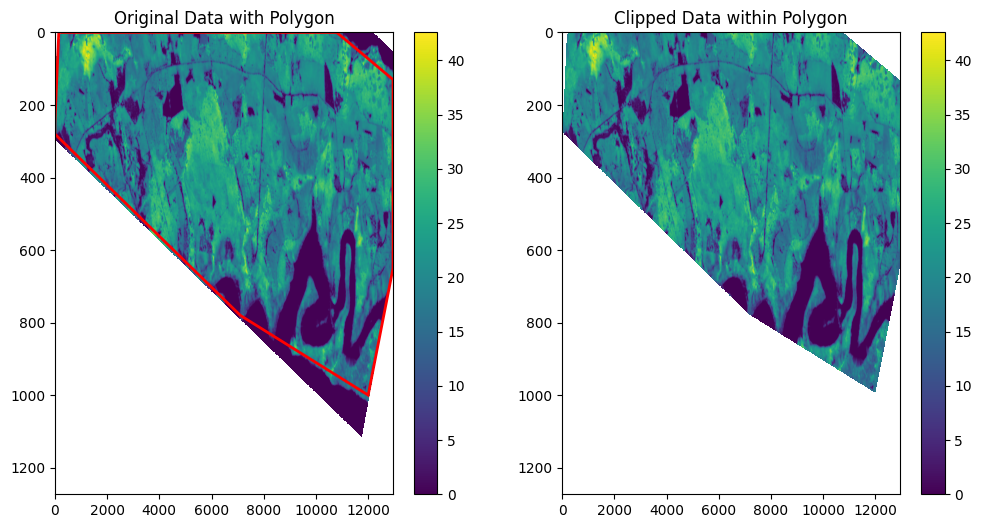

In [44]:
clipped_data = np.full(lidar_chm.shape, np.nan)
clipped_data[mask] = lidar_chm[mask]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title('Original Data with Polygon')
c1 = ax1.imshow(lidar_chm, cmap='viridis', aspect='auto')
fig.colorbar(c1, ax=ax1)

polygon_patch = MplPolygon(polygon_coords, closed=True, edgecolor='red', fill=False, linewidth=2)
ax1.add_patch(polygon_patch)

ax2.set_title('Clipped Data within Polygon')
c2 = ax2.imshow(clipped_data, cmap='viridis', aspect='auto') 
fig.colorbar(c2, ax=ax2)

plt.show()

### Crop for SE

lidar_chm.shape (1306, 13530)
ground_range_axis (1306, 1)
azimuth_axis (1, 13530)
ground_range_axis.min 510.0
ground_range_axis.max 4425.0
azimuth_axis.min -3646.0
azimuth_axis.max 3118.5


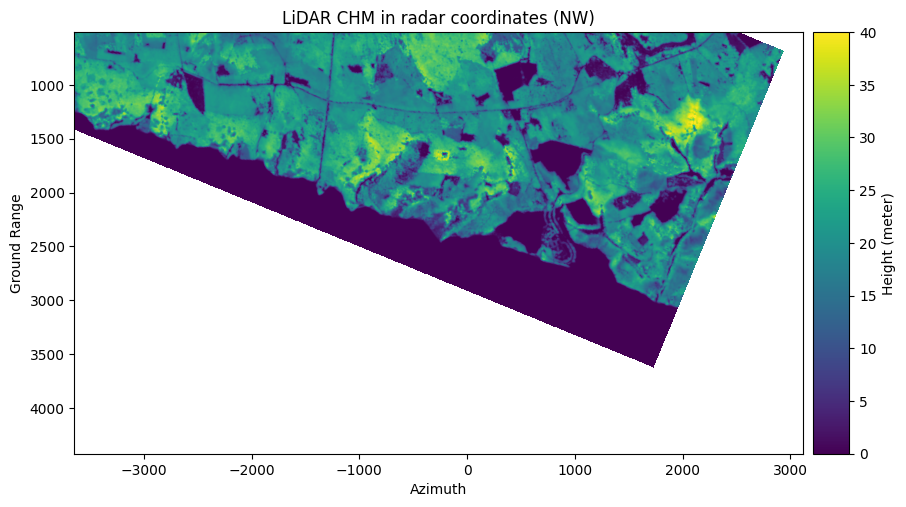

In [45]:
lidar_radar = loadmat(lidar_SE_path)  # Change NW or SE as needed

lidar_chm = lidar_radar['CHM_lidar']
ground_range_axis_lidar = lidar_radar['ground_range_axis']
azimuth_axis_lidar = lidar_radar['azimuth_axis']

print('lidar_chm.shape', lidar_chm.shape)
print('ground_range_axis', ground_range_axis_lidar.shape)
print('azimuth_axis', azimuth_axis_lidar.shape)

print('ground_range_axis.min', ground_range_axis_lidar.min())
print('ground_range_axis.max', ground_range_axis_lidar.max())
print('azimuth_axis.min', azimuth_axis_lidar.min())
print('azimuth_axis.max', azimuth_axis_lidar.max())

# Plotting
plt.figure(figsize=(10, 6))
ax = plt.gca()  # Get the current Axes instance

# Plot the lidar CHM data
im = ax.imshow(lidar_chm, cmap="viridis", vmin=0, vmax=40,
               extent=[azimuth_axis_lidar.min(), azimuth_axis_lidar.max(), 
                       ground_range_axis_lidar.max(), ground_range_axis_lidar.min()])

# Create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be 0.1 inch.
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)

# Create color bar in the new axis
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Height (meter)')

ax.set_xlabel('Azimuth')
ax.set_ylabel('Ground Range')
ax.set_title('LiDAR CHM in radar coordinates (NW)')

plt.show()

In [62]:
from shapely.geometry import Point, Polygon
# Define the coordinates of the polygon (example polygon coordinates)
polygon_coords = [(0, 0), (12100, 0), (13020, 60), (11100, 850), (0, 220)]
polygon = Polygon(polygon_coords)

In [63]:
# Access the correct coordinate variables (assuming they are named 'x' and 'y')
rows, cols = lidar_chm.shape
mask = np.zeros(lidar_chm.shape, dtype=bool)
x_coords, y_coords = np.meshgrid(np.arange(cols), np.arange(rows))

In [64]:
import xarray as xr
from matplotlib.patches import Polygon as MplPolygon

# Check if each point is inside the polygon
for i in range(rows):
    for j in range(cols):
        point = Point(x_coords[i, j], y_coords[i, j])
        if polygon.contains(point):
            mask[i, j] = True

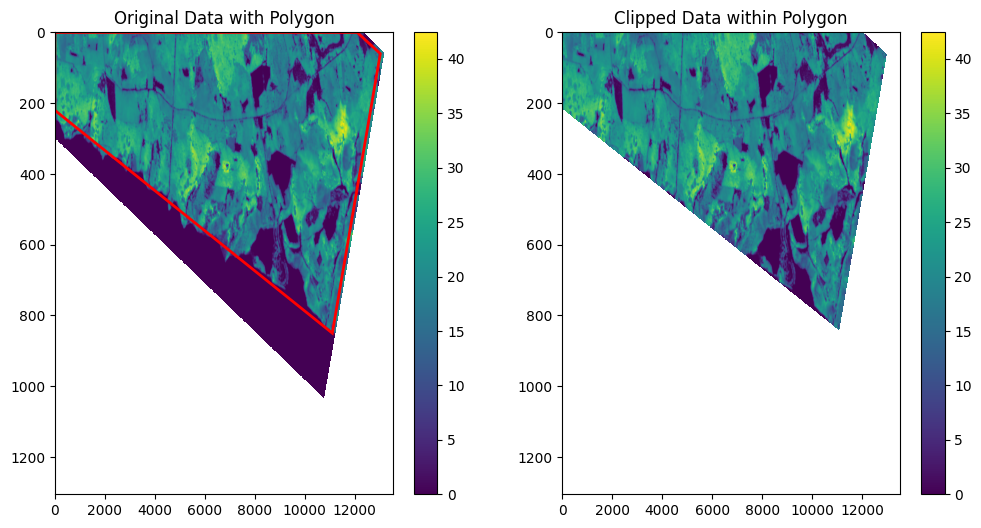

In [65]:
clipped_data = np.full(lidar_chm.shape, np.nan)
clipped_data[mask] = lidar_chm[mask]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title('Original Data with Polygon')
c1 = ax1.imshow(lidar_chm, cmap='viridis', aspect='auto')
fig.colorbar(c1, ax=ax1)

polygon_patch = MplPolygon(polygon_coords, closed=True, edgecolor='red', fill=False, linewidth=2)
ax1.add_patch(polygon_patch)

ax2.set_title('Clipped Data within Polygon')
c2 = ax2.imshow(clipped_data, cmap='viridis', aspect='auto') 
fig.colorbar(c2, ax=ax2)

plt.show()

## Plot and Check intensity and LiDAR CHM images

In [10]:
import pandas as pd

x_dim, y_dim = BC.shape # 12953, 1274
records = []

for x in range(x_dim):
    for y in range(y_dim):
        real_value = RealPart_SAR_CPLX[x, y]
        imaginary_value = ImagPart_SAR_CPLX[x,y]
        intensity = BC[x,y]
        lidar_chm_value = lidar_chm[y,x]
        records.append([x, y, real_value, imaginary_value, intensity, lidar_chm_value])
        
# Create DataFrame
df = pd.DataFrame(records, columns=['azimuth', 'ground_range', 'real', 'imaginary', 'intensity', 'lidar_chm'])
print('df.shape',df.shape)

df.shape (16502122, 6)


In [155]:
print(x_dim, y_dim)

12953 1274


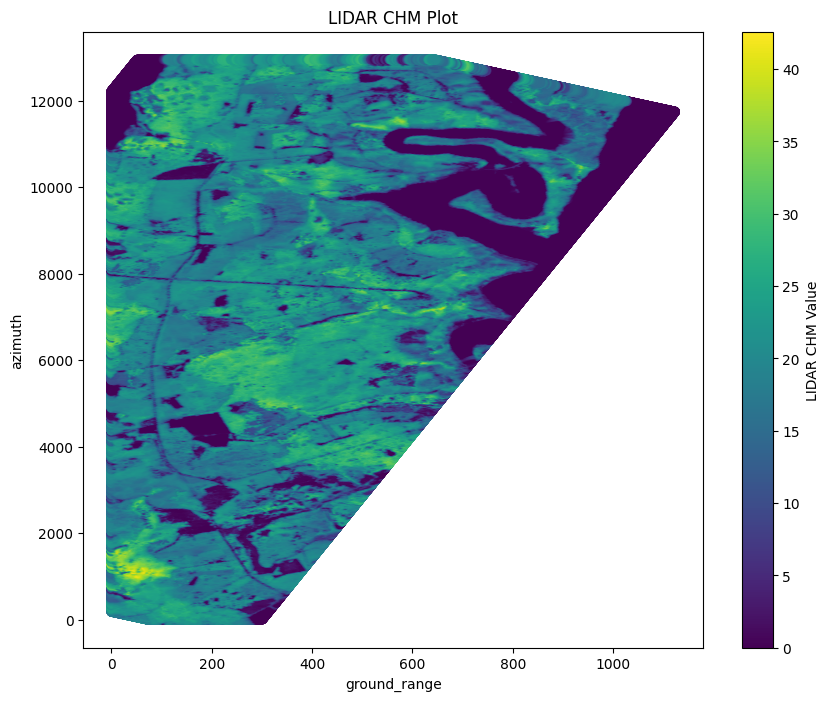

In [153]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['ground_range'], df['azimuth'], c=df['lidar_chm'], cmap='viridis')
plt.colorbar(scatter, label='LIDAR CHM Value')
plt.xlabel('ground_range')
plt.ylabel('azimuth')
plt.title('LIDAR CHM Plot')
plt.show()


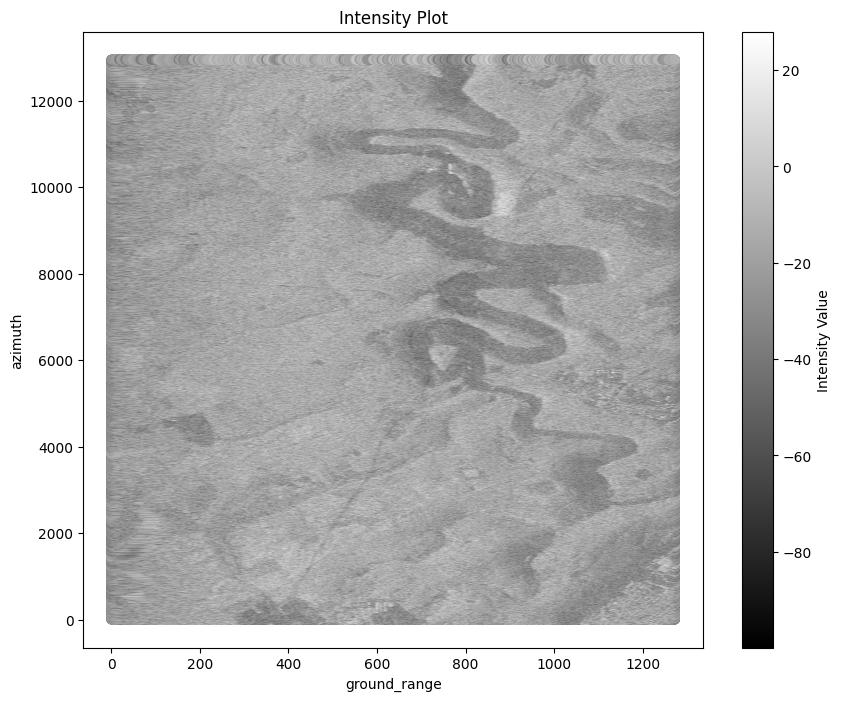

In [154]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['ground_range'], df['azimuth'], c=df['intensity'], cmap='gray')
plt.colorbar(scatter, label='Intensity Value')
plt.xlabel('ground_range')
plt.ylabel('azimuth')
plt.title('Intensity Plot')
plt.show()


## SE

df.shape (17670180, 6)


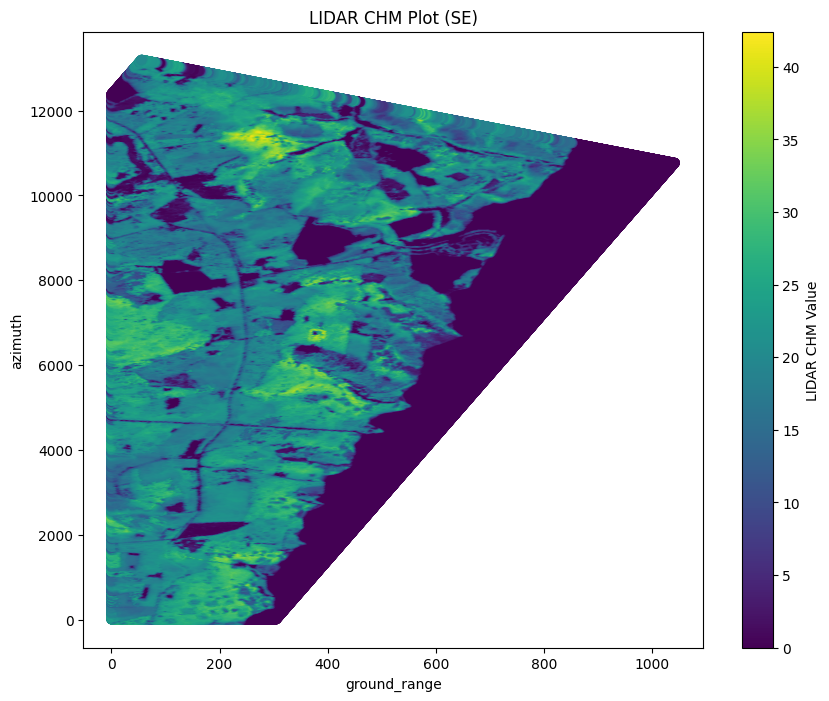

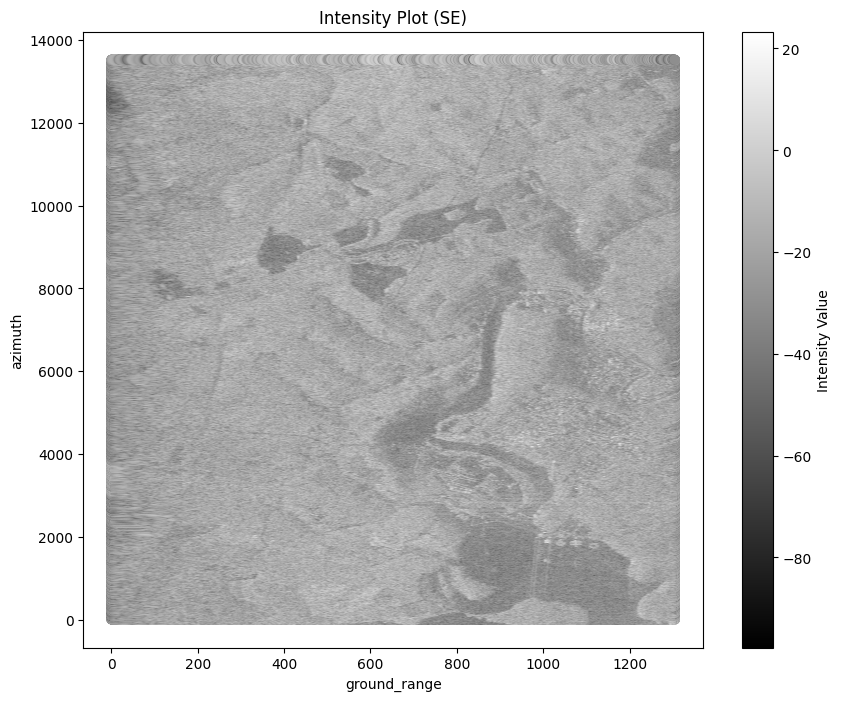

In [158]:
lidar_radar = loadmat(lidar_SE_path) ## change NW or SE

lidar_chm = lidar_radar['CHM_lidar']
ground_range_axis_lidar = lidar_radar['ground_range_axis']
azimuth_axis_lidar = lidar_radar['azimuth_axis']

nc_data = xr.open_dataset(slc_fullpath_SE)

azimuth_axis_slc = nc_data.variables['CrossRange']
ground_range_axis_slc = nc_data.variables['GroundRange']

# reads a single netCDF file
RealPart_SAR_CPLX = nc_data.variables['SigmaImageSingleLookRealPart'].to_numpy()
RealPart_SAR_CPLX_2 = RealPart_SAR_CPLX ** 2
ImagPart_SAR_CPLX = nc_data.variables["SigmaImageSingleLookImagPart"].to_numpy()
ImagPart_SAR_CPLX_2 = ImagPart_SAR_CPLX ** 2
DN_2 = RealPart_SAR_CPLX_2 + ImagPart_SAR_CPLX_2
DN = np.sqrt(DN_2)
BC = 10*np.log(DN)

azimuth_axis_lidar_matrix, ground_range_axis_lidar_matrix = np.meshgrid(azimuth_axis_lidar, ground_range_axis_lidar)
azimuth_axis_slc_matrix, ground_range_axis_slc_matrix = np.meshgrid(azimuth_axis_slc, ground_range_axis_slc)

x_dim, y_dim = BC.shape # 12953, 1274
records = []

for x in range(x_dim):
    for y in range(y_dim):
        real_value = RealPart_SAR_CPLX[x, y]
        imaginary_value = ImagPart_SAR_CPLX[x,y]
        intensity = BC[x,y]
        lidar_chm_value = lidar_chm[y,x]
        records.append([x, y, real_value, imaginary_value, intensity, lidar_chm_value])
        
# Create DataFrame
df = pd.DataFrame(records, columns=['azimuth', 'ground_range', 'real', 'imaginary', 'intensity', 'lidar_chm'])
print('df.shape',df.shape)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['ground_range'], df['azimuth'], c=df['lidar_chm'], cmap='viridis')
plt.colorbar(scatter, label='LIDAR CHM Value')
plt.xlabel('ground_range')
plt.ylabel('azimuth')
plt.title('LIDAR CHM Plot (SE)')
plt.show()

plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['ground_range'], df['azimuth'], c=df['intensity'], cmap='gray')
plt.colorbar(scatter, label='Intensity Value')
plt.xlabel('ground_range')
plt.ylabel('azimuth')
plt.title('Intensity Plot (SE)')
plt.show()
